# BTL02 – Notebook tái lập huấn luyện & đánh giá FER2013 (PyTorch)

- **Phụ trách**: `TV3 – Võ Hoàng Bảo` (Nhiệm vụ **T10**)
- **Phối hợp**: `TV2 – Lê Phan Nguyên Hải` (`C1`: chạy lại Restart & Run All trên máy riêng), `TV4 – Huỳnh Viễn Thông` (`C2`: soát lời giải thích từng bước)
- **Kiểm thử độc lập**: `TV1 – Đoàn Trung Kiên` (`T`)

## Mục tiêu & quy chuẩn (Mục 9.5 `PHAN_CONG_NHIEM_VU.md`)
1. Gọi trực tiếp các hàm trong `src/` (`src/data/loader.py`, `src/models/cnn.py`, `src/engine/trainer.py`, `src/engine/evaluate.py`, `src/visual/plots.py`), **không** chép lại logic huấn luyện và **không** chạy qua subprocess.
2. Huấn luyện chạy trực tiếp trong kernel của notebook để `logging` ghi đồng thời ra **stdout (output của cell)** và file **`run.log`**.
3. Không sử dụng đường dẫn tuyệt đối; chỉ dùng tập `Training` và `PublicTest` (tuyệt đối không chạm `PrivateTest`).
4. Tự động cấp mã `exp_id` mới (`_nb-NNN_s<seed>`) khi chạy lại `Kernel -> Restart & Run All`, không ghi đè run cũ.
5. Cuối notebook đọc lại `history.csv` để vẽ đường cong, in `metrics.json`, tổng thời gian, SHA-256 của `run.log` & `history.csv`, và kiểm chứng bằng `assert` số dòng epoch trong `run.log` khớp số dòng `history.csv`.

## Bước 1. Khởi tạo môi trường, thông tin máy chạy & kiểm tra toàn vẹn dữ liệu
Ô này xác định thư mục gốc `BTL02/`, nạp tham số chạy (mặc định `group="_nb"`, `task_id="T10"`, `epochs=2` để kiểm chứng tái lập nhanh mà không ảnh hưởng nhóm `baseline`), sau đó in đầy đủ metadata: thành viên, hostname, GPU, phiên bản PyTorch/CUDA, `git_commit`, SHA-256 của `data/fer2013.csv`, `seed` và thời điểm bắt đầu.

In [1]:
# Phụ trách: TV3 – Võ Hoàng Bảo. Nhiệm vụ T10.
import csv
import getpass
import json
import os
import platform
import re
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path

# Tìm thư mục gốc BTL02 tương đối (chạy được cả từ BTL02/ lẫn BTL02/notebooks/)
_cwd = Path.cwd().resolve()
ROOT = _cwd if (_cwd / "src").is_dir() else _cwd.parent
assert (ROOT / "src" / "engine" / "trainer.py").is_file(), f"Không tìm thấy thư mục BTL02 từ {_cwd}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
from IPython.display import Image, display

from src.data.loader import make_loaders
from src.engine.evaluate import metrics as eval_metrics, predict
from src.engine.trainer import fit
from src.models import build_model, n_params
from src.run_experiment import _next_number, collect_row, plot_run
from src.utils.io import append_csv_row, rel, sha256_file, write_json
from src.utils.seed import set_seed
from src.visual.plots import plot_curves

MEMBER = os.environ.get("BTL02_MEMBER", "TV3")
GROUP = os.environ.get("BTL02_GROUP", "_nb")
TASK_ID = os.environ.get("BTL02_TASK_ID", "T10")
VARIANT = os.environ.get("BTL02_VARIANT", "repro_2ep")
SEED = int(os.environ.get("BTL02_SEED", "0"))
EPOCHS = int(os.environ.get("BTL02_EPOCHS", "2"))
RECORD_TRACKING = os.environ.get("BTL02_RECORD_TRACKING", "1") == "1"

def _now() -> str:
    return datetime.now().astimezone().isoformat(timespec="seconds")

def _git(*args: str) -> str:
    try:
        return subprocess.run(["git", *args], cwd=ROOT, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return ""

data_csv = ROOT / "data" / "fer2013.csv"
assert data_csv.is_file(), f"Chưa có dữ liệu cục bộ tại {data_csv}. Đặt fer2013.csv trước khi chạy notebook."

git_commit = _git("rev-parse", "--short=8", "HEAD")
if git_commit and _git("status", "--porcelain", "--", "src", "configs"):
    git_commit += "-dirty"

env_info = {
    "member": MEMBER,
    "hostname": platform.node(),
    "os_user": getpass.getuser(),
    "git_user": _git("config", "user.name"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "git_commit": git_commit,
    "dataset_sha256": sha256_file(data_csv),
    "seed": SEED,
    "started_at": _now(),
}
print(json.dumps(env_info, ensure_ascii=False, indent=2))

{
  "member": "TV3",
  "hostname": "Hbao",
  "os_user": "ADMIN",
  "git_user": "hoangbao2908",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "torch": "2.6.0+cu124",
  "cuda": "12.4",
  "git_commit": "f9ddc703",
  "dataset_sha256": "3b8d9617d1017f34733c8f2474d7784c563ce86c40a86ac12c2d37cc968f871b",
  "seed": 0,
  "started_at": "2026-11-25T10:09:11+07:00"
}


## Bước 2. Cấu hình thực nghiệm, nạp dữ liệu (`Training` / `PublicTest`) và khởi tạo mô hình
- Cố định mọi nguồn ngẫu nhiên bằng `set_seed(SEED)`.
- Nạp `train_loader` và `val_loader` bằng `make_loaders(cfg)` (`num_workers=0` phù hợp Windows, mean/std chỉ tính từ `Training`, không đọc `PrivateTest`).
- Khởi tạo mô hình CNN `baseline` từ `build_model("baseline")` và cấp thư mục `results/<group>/<exp_id>/` mới để không ghi đè lần chạy trước.

In [2]:
exp_csv = ROOT / "tracking" / "experiments.csv"
with open(exp_csv, encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    exp_header = reader.fieldnames
    known_ids = [r["exp_id"] for r in reader]

run_num = _next_number(ROOT, GROUP, known_ids)
EXP_ID = f"{GROUP}-{run_num:03d}_s{SEED}"
RUN_DIR = ROOT / "results" / GROUP / EXP_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

cfg = {
    "model": "baseline",
    "epochs": EPOCHS,
    "batch_size": 128,
    "optimizer": "sgd",
    "lr": 0.01,
    "momentum": 0.9,
    "nesterov": True,
    "weight_decay": 0.0005,
    "scheduler": "plateau",
    "factor": 0.5,
    "lr_patience": 5,
    "early_stopping_patience": 15,
    "label_smoothing": 0.0,
    "augmentation": "flip_affine",
    "amp": True,
    "num_workers": 0,
    "seed": SEED,
    "variant": VARIANT,
    "exp_id": EXP_ID,
}

set_seed(SEED)
train_loader, val_loader = make_loaders(cfg)
model = build_model(cfg["model"])
total_params = n_params(model)

meta = {
    "exp_id": EXP_ID,
    "task_id": TASK_ID,
    "group": GROUP,
    "variant": VARIANT,
    "member": env_info["member"],
    "hostname": env_info["hostname"],
    "os_user": env_info["os_user"],
    "git_user": env_info["git_user"],
    "gpu": env_info["gpu"],
    "torch": env_info["torch"],
    "cuda": env_info["cuda"],
    "git_commit": env_info["git_commit"],
    "dataset_sha256": env_info["dataset_sha256"],
    "started_at": env_info["started_at"],
    "finished_at": None,
    "duration_s": None,
    "n_params": total_params,
    "config_path": "notebooks/BTL02_reproducible.ipynb",
    "cfg": cfg,
}
write_json(RUN_DIR / "config.json", meta)

print(f"exp_id        : {EXP_ID}")
print(f"run_dir       : {rel(RUN_DIR, ROOT)}")
print(f"Train / Val   : {len(train_loader.dataset)} / {len(val_loader.dataset)} ảnh")
print(f"Tham số model : {total_params:,}")

exp_id        : _nb-001_s0
run_dir       : results/_nb/_nb-001_s0
Train / Val   : 28709 / 3589 ảnh
Tham số model : 5,867,847


## Bước 3. Huấn luyện trực tiếp trong kernel bằng `fit()`
Hàm `fit()` trong `src/engine/trainer.py` ghi đồng thời từng dòng epoch ra output của ô này và file `run.log`, ghi `history.csv`, áp dụng luật giữ/xóa `best.pt` tự động và lưu `metrics.json`.

In [3]:
t0 = time.perf_counter()
train_result = fit(model, train_loader, val_loader, cfg, RUN_DIR)
duration_s = round(time.perf_counter() - t0, 3)

meta.update(finished_at=_now(), duration_s=duration_s)
write_json(RUN_DIR / "config.json", meta)

if RECORD_TRACKING:
    plot_run(RUN_DIR, ROOT)
    row = collect_row(RUN_DIR, ROOT)
    row["notebook_path"] = f"notebooks/executed/{EXP_ID}.ipynb"
    append_csv_row(exp_csv, exp_header, row)
    print(f"Đã ghi dòng {EXP_ID} vào tracking/experiments.csv (notebook_path={row['notebook_path']})")
else:
    plot_curves(RUN_DIR / "history.csv", RUN_DIR / "curves.png", title=EXP_ID)
    print("BTL02_RECORD_TRACKING=0: bỏ qua ghi tracking/experiments.csv và figures_manifest.csv.")

2026-11-25T10:09:43+07:00 | _nb-001_s0 | START | device=cuda | epochs=2 | amp=True | optimizer=sgd | lr=0.01 | seed=0


2026-11-25T10:10:04+07:00 | _nb-001_s0 | 1/2 | train_loss=1.8166 | val_loss=1.7233 | val_acc=0.3129 | val_macro_f1=0.1756 | lr=0.01 | 21.7s | ok


2026-11-25T10:10:25+07:00 | _nb-001_s0 | 2/2 | train_loss=1.7271 | val_loss=1.5459 | val_acc=0.3876 | val_macro_f1=0.2813 | lr=0.01 | 20.2s | ok


2026-11-25T10:10:25+07:00 | _nb-001_s0 | END | status=Completed | reason=OK | stopped_by=max_epochs | best_epoch=2 | train_time_s=43.272


Đã ghi dòng _nb-001_s0 vào tracking/experiments.csv (notebook_path=notebooks/executed/_nb-001_s0.ipynb)


## Bước 4. Đánh giá độc lập trên `PublicTest` bằng `src/engine/evaluate.py`
Nạp lại trọng số `best.pt` đã lưu, gọi `predict()` và `metrics()` trên `val_loader` (`PublicTest`) để xác nhận độ chính xác và `macro-F1` khớp với `metrics.json` do `trainer.py` ghi.

In [4]:
best_pt = RUN_DIR / "best.pt"
assert best_pt.is_file(), "Không tìm thấy best.pt sau huấn luyện hợp lệ"

eval_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
eval_model = build_model(cfg["model"]).to(eval_device)
eval_model.load_state_dict(torch.load(best_pt, map_location=eval_device, weights_only=True))

y_true, y_prob = predict(eval_model, val_loader, tta=False, device=eval_device, amp=cfg["amp"])
eval_res = eval_metrics(y_true, y_prob)
print(f"Evaluate PublicTest -> acc={eval_res['acc']:.6f}, macro_f1={eval_res['macro_f1']:.6f}")
assert abs(eval_res["acc"] - train_result["best_val_acc"]) < 1e-4, (
    f"Lệch val_acc giữa evaluate.py ({eval_res['acc']}) và metrics.json ({train_result['best_val_acc']})"
)

Evaluate PublicTest -> acc=0.387573, macro_f1=0.281308


## Bước 5. Kiểm chứng cuối (biểu đồ từ `history.csv`, SHA-256 & `assert` khớp log)
Theo quy chuẩn mục 9.5:
- Vẽ lại đường cong Train/Val loss & acc từ `history.csv`.
- In toàn bộ `metrics.json`, tổng thời gian `tong_thoi_gian_s`, SHA-256 của `run.log` và `history.csv`.
- Kiểm chứng bằng **`assert`**: số dòng epoch trong `run.log` == số dòng trong `history.csv`, và chỉ số tốt nhất trong `history.csv` khớp `metrics.json`.

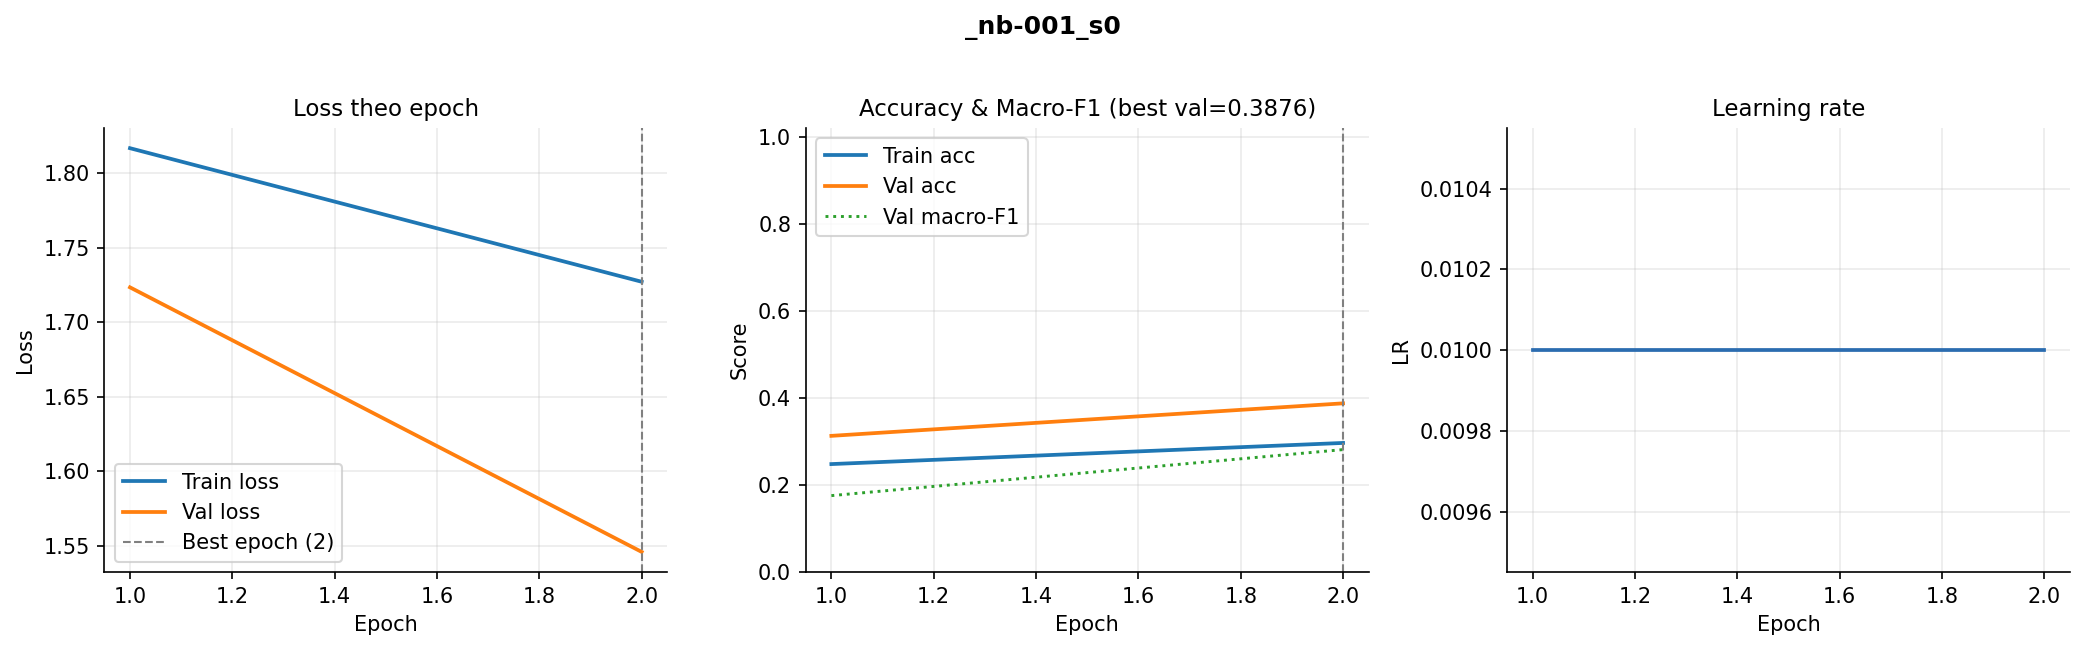

=== metrics.json ===
{
  "exp_id": "_nb-001_s0",
  "status": "Completed",
  "stopped_by": "max_epochs",
  "epochs_run": 2,
  "best_epoch": 2,
  "best_val_acc": 0.38757314015045974,
  "best_val_macro_f1": 0.28130794160089745,
  "best_val_loss": 1.5458848325612984,
  "train_loss_cuoi": 1.7270526011007001,
  "train_acc_cuoi": 0.29663171827649865,
  "val_loss_cuoi": 1.5458848325612984,
  "epoch_time_s_tb": 20.941000000000003,
  "train_time_s": 43.272,
  "weights_quyet_dinh": "KEEP",
  "weights_ma_ly_do": "OK",
  "weights_sha256": "97323814329c61ab8e52031db4fdd538a5db90fb30704f25957db2ce01f0f53f",
  "weights_size_mb": 22.404
}
tong_thoi_gian_s : 43.276
sha256(run.log)  : 72f60ba3e4642378d73aa13c1251688324fc4a17b0e63b5662961255c1daad0b
sha256(history)  : 495a680ff474af4d4b358311820deb925f680f37270a783e5a732301ae84c015
Số dòng epoch    : run.log=2 | history.csv=2
PASS: Toàn bộ kiểm chứng tái lập (run.log, history.csv, metrics.json, best.pt) đều khớp!


In [5]:
history_path = RUN_DIR / "history.csv"
log_path = RUN_DIR / "run.log"
metrics_path = RUN_DIR / "metrics.json"
curves_png = RUN_DIR / "curves.png"

if not curves_png.is_file():
    plot_curves(history_path, curves_png, title=EXP_ID)

display(Image(filename=str(curves_png)))

with open(history_path, encoding="utf-8", newline="") as f:
    hist_rows = list(csv.DictReader(f))

log_lines = log_path.read_text(encoding="utf-8").splitlines()
epoch_pat = re.compile(rf"\|\s*{re.escape(EXP_ID)}\s*\|\s*\d+/{EPOCHS}\s*\|")
log_epoch_lines = [ln for ln in log_lines if epoch_pat.search(ln)]

metrics_obj = json.loads(metrics_path.read_text(encoding="utf-8"))
best_hist_acc = max(float(r["val_acc"]) for r in hist_rows)

print("=== metrics.json ===")
print(json.dumps(metrics_obj, ensure_ascii=False, indent=2))
print(f"tong_thoi_gian_s : {duration_s}")
print(f"sha256(run.log)  : {sha256_file(log_path)}")
print(f"sha256(history)  : {sha256_file(history_path)}")
print(f"Số dòng epoch    : run.log={len(log_epoch_lines)} | history.csv={len(hist_rows)}")

assert len(log_epoch_lines) == len(hist_rows) == metrics_obj["epochs_run"], (
    f"Không khớp số dòng epoch: run.log={len(log_epoch_lines)}, history.csv={len(hist_rows)}, "
    f"metrics.json={metrics_obj['epochs_run']}"
)
assert abs(best_hist_acc - metrics_obj["best_val_acc"]) < 1e-12, "best_val_acc không khớp history.csv"
assert metrics_obj["status"] == "Completed" and metrics_obj["weights_quyet_dinh"] == "KEEP"
print("PASS: Toàn bộ kiểm chứng tái lập (run.log, history.csv, metrics.json, best.pt) đều khớp!")